# Sigue un mineral de cobre por trituración y molienda

**Pregunta:** Al cambiar el tratamiento de alimentación fresca, ¿qué salidas de tamaño y energía responden en el circuito cerrado?

Nivel: 1. Requisitos previos: Ninguno; comienza aquí. Tiempo de lectura: 18 minutos.

## Objetivos

Partiendo de un mineral OreFlow declarado y su punto operativo nominal, sigue el tamaño de alimentación a través del circuito de conminución. Distingue un registro simulado de planta de una medición y reconoce las magnitudes que calcula el motor.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Para la lección de nivel 1 sobre 01-comminution, registra las versiones fijadas antes de ejecutar el análisis; así se puede reconstruir el entorno que produjo cada tabla y figura.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores del proyecto OreFlow. Fuente: escenario versionado y de autoría propia de pórfido cuprífero blando (licencia MIT del proyecto), `data/derived/cases/copper_porphyry_soft.json`; es un escenario de modelo, no un ensayo de mina ni una medición de planta. Los resúmenes de partículas provienen de casos construidos públicos de HZDR; consulta `data/derived/source/hzdr_particle_benchmark.json` y el dossier de procedencia HZDR. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

El motor representa el tamaño en una malla logarítmica fija. La trituración transforma la distribución mediante el modelo de clasificación Whiten. La molienda aplica una función de selección específica por energía y una matriz de fractura; el clasificador envía cada clase de tamaño al rebose o al reciclaje. En estado estacionario, la alimentación fresca coincide con los productos finales dentro de la tolerancia del balance unitario. Aquí llamamos a `simulate` del pipeline OreFlow; no reimplementamos ecuaciones de conminución.

Importa el catálogo de casos OreFlow y el simulador del pipeline del repositorio. El punto nominal es el estado operativo documentado del caso; el solver devuelve el mismo resultado estructurado que usa el proceso de bake.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

# Paso ejecutable del método OreFlow explicado en la celda anterior.
case = next(item for item in CASES if item.id == "copper_porphyry_soft")
result = simulate(case.ore, case.plant, case.nominal)
print("familia:", case.plant.family)
print("caudal:", case.nominal.throughput_tph, "t/h")
print("F80 de alimentación:", round(result.metrics["crusher_feed_f80_um"], 1), "um")
print("P80 de producto:", round(result.grinding.p80_um, 1), "um")
print("energía de molienda:", round(result.grinding.specific_energy_kwh_t, 2), "kWh/t")


familia: rougher
caudal: 720.0 t/h
F80 de alimentación: 60094.9 um
P80 de producto: 150.0 um
energía de molienda: 8.97 kWh/t


Inspecciona las distribuciones acumuladas de pasante en los límites identificados del circuito. P80 es un percentil de una distribución; no se infiere de una partícula representativa.

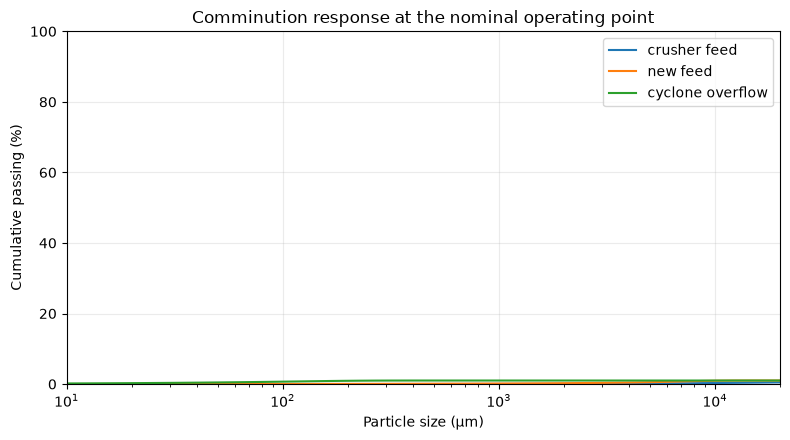

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Paso ejecutable del método OreFlow explicado en la celda anterior.
size = np.asarray(result.curves["size_um"])
psd = result.curves["psd"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for stream in ("crusher_feed", "new_feed", "cyclone_overflow"):
    ax.plot(size, psd[stream], label=stream.replace("_", " "))
ax.set_xscale("log")
ax.set_xlim(10, 20_000)
ax.set_ylim(0, 100)
ax.set(
    xlabel="Particle size (µm)",
    ylabel="Cumulative passing (%)",
    title="Comminution response at the nominal operating point",
)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()


La figura 11 de nivel 1 sobre 01 comminution informa salidas de puntos operativos resueltos por separado. En la figura 11 de nivel 1 sobre 01 comminution, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 11 de nivel 1 sobre 01 comminution, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 11 solo guía la comparación.

Lee las métricas calculadas por etapa y el residuo máximo del balance. Un error de cierre pequeño verifica conservación numérica en esta corrida; no valida el modelo frente a una planta.

In [4]:
from IPython.display import display
import pandas as pd

# Paso ejecutable del método OreFlow explicado en la celda anterior.
metrics = result.metrics
rows = [
    ("Crusher feed F80", metrics["crusher_feed_f80_um"], "µm"),
    ("Crusher product P80", metrics["crusher_p80_um"], "µm"),
    ("Circuit product P80", metrics["p80_um"], "µm"),
    ("Specific grinding energy", metrics["specific_energy_grinding_kwh_t"], "kWh/t"),
    ("Maximum relative balance error", result.balance["max_relative_error"], "fraction"),
]
display(pd.DataFrame(rows, columns=["Quantity", "Value", "Unit"]))


,Quantity,Value,Unit
0,Crusher feed F80,6.009494e+04,µm
1,Crusher product P80,8.417932e+03,µm
2,Circuit product P80,1.500000e+02,µm
3,Specific grinding energy,8.967354e+00,kWh/t
4,Maximum relative balance error,1.525693e-13,fraction


En el caso de nivel 1 sobre 01 comminution, la corrida con 0.9× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 1 sobre 01 comminution, con 0.9× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [5]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


En el caso de nivel 1 sobre 01 comminution, la corrida con 1.1× el tratamiento nominal cambia la alimentación fresca y mantiene los demás controles en su punto nominal de autoría. En el caso de nivel 1 sobre 01 comminution, con 1.1× de alimentación, recuperación, tamaño y energía son salidas acopladas del circuito resuelto.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


En la lección de nivel 1 sobre 01 comminution, la lectura del gráfico 1 considera en esta figura del nivel 1 sobre 01 comminution, compara la recuperación con el P80 de producto al variar el tratamiento. En la lección de nivel 1 sobre 01 comminution, la lectura del gráfico 2 considera los ejes separan unidades distintas, así que el cambio describe el caso de autoría propia y no una tendencia empírica de planta. En la lección de nivel 1 sobre 01 comminution, la lectura del gráfico 3 considera el punto nominal sirve como referencia para los ajustes vecinos. En la lección de nivel 1 sobre 01 comminution, la lectura del gráfico 4 considera en «Sigue un mineral de cobre por trituración y molienda», cada punto procede de una evaluación independiente del motor y las líneas solo guían la vista entre ajustes probados.

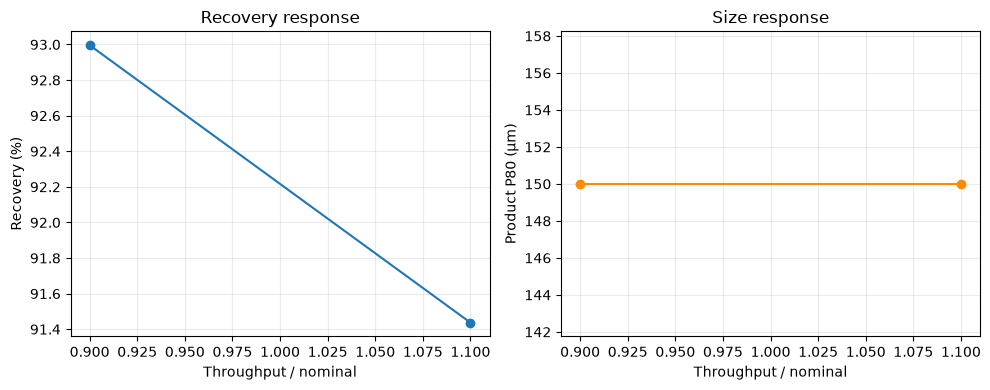

In [7]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.9, 1.1]
runs = [response_0_9, response_1_1]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


La figura 19 de nivel 1 sobre 01 comminution informa salidas de puntos operativos resueltos por separado. En la figura 19 de nivel 1 sobre 01 comminution, cada marca es una evaluación separada del modelo en el ajuste indicado. En la figura 19 de nivel 1 sobre 01 comminution, contrasta recuperación, tamaño y energía con el contrato. La línea de la figura 19 solo guía la comparación.

En el nivel 1 de 01 comminution, la interpretación 1 es que la conminución acopla fractura, clasificación y recirculación. En el nivel 1 de 01 comminution, la interpretación 2 es que un cambio en la alimentación fresca puede acercar el molino al límite de potencia instalada, modificar la distribución de tamaños que entra al clasificador y cambiar la carga circulante. En el nivel 1 de 01 comminution, la interpretación 3 es que el P80 por sí solo no describe toda la distribución. En el nivel 1 de 01 comminution, la interpretación 4 es que por eso se deben leer conjuntamente las curvas acumuladas y la auditoría por flujo del motor. En el nivel 1 de 01 comminution, la interpretación 5 es que la ecuación del índice de trabajo Bond es una relación empírica de circuito estándar con una base definida de tamaños de alimentación y producto. En el nivel 1 de 01 comminution, la interpretación 6 es que no es una ley mecanicista de cada partícula. En el nivel 1 de 01 comminution, la interpretación 7 es que rittinger y Kick expresan supuestos de escala diferentes y deben compararse con un punto de calibración común. En el nivel 1 de 01 comminution, la interpretación 8 es que cerrar el balance de masa es necesario para un cálculo creíble, pero no demuestra que los parámetros de fractura o selección representen una planta en operación. En el nivel 1 de 01 comminution, la interpretación 9 es que la validación independiente necesita distribuciones de tamaño medidas, tratamiento, potencia y calibración específica del mineral, con un protocolo de muestreo acordado.

## Resultados

**Respuesta:** En esta lección de nivel 1 sobre 01 comminution, el circuito ejecutado informa una recuperación de 92.996 por ciento para «Sigue un mineral de cobre por trituración y molienda» en el primer tratamiento controlado.

La curva PSD muestra la respuesta de tamaño del modelo en tres flujos identificados; no muestra trayectorias de partículas individuales. El residuo del balance prueba conservación dentro de este cálculo estacionario de autoría propia. Ni este caso ni sus parámetros están calibrados con una planta.

## Resumen

Ejecutaste el mismo solver de circuito que usa OreFlow, seguiste una distribución de tamaños y leíste su verificación de conservación. Distingue el cierre del modelo (consistencia interna) de la validación frente a datos medidos de planta.

## Referencias

- https://doi.org/10.1016/0301-7516(80)90034-4
- https://github.com/fsantibanezleal/CAOS_OreFlow/tree/develop/data/derived
- https://doi.org/10.1016/0301-7516(80)90034-4